# 📘 7.5 Higher-Order Ordinary Differential Equations

### Converting mechanical equations into coupled first-order state systems

Many mechanical models contain derivatives above first order. Newton's second law
naturally produces acceleration, beam and vibration models may contain still higher
derivatives, and several physical components may be coupled.

Standard IVP solvers such as `solve_ivp` advance a **first-order state vector**. A
higher-order ODE is therefore rewritten as a system of first-order equations by
introducing clearly defined state variables.

This notebook uses a mass–spring–damper system to develop that conversion, solve and
validate the vector IVP, interpret damping and energy, connect partially observed data
points to hidden states, and calibrate uncertain stiffness and damping parameters.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* identify the order of an ODE from its highest derivative;
* convert a second-order mechanical ODE into two first-order state equations;
* specify the initial conditions required by a second-order IVP;
* implement a vector right-hand-side function for `solve_ivp`;
* verify an underdamped numerical response against an analytical solution;
* interpret natural frequency, damping ratio and damping regime;
* use phase-space and energy plots to assess physical behaviour;
* represent the model in state-space matrix form;
* distinguish model states from measured outputs;
* calibrate stiffness and damping from displacement data and validate them on a new
  experiment; and
* generalise the state conversion to an $n$th-order scalar ODE.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO1:** Assess the suitability and limitations of numerical analysis and machine
  learning tools for engineering applications.
* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools
  to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common
  engineering problems, and evaluate performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* SciPy — [`scipy.integrate.solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)
* SciPy — [`scipy.optimize.least_squares`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html)
* NumPy — [`numpy.gradient`](https://numpy.org/doc/stable/reference/generated/numpy.gradient.html)


## 📂 7.5.0 How to use this notebook

Run every code cell in order. No editing or input is required. Pause whenever a new
state variable is introduced and check its physical meaning and units.

> ### 🧭 Theory preface
> Rewriting a higher-order ODE does not add new physics. It reorganises the same
> equation into a form a first-order solver can advance. We will define every new
> symbol before using it and show each substitution explicitly.
>
> The state variables are not arbitrary machine-learning features. They are the
> minimum evolving physical quantities needed to determine the future response under
> the model. Some states may be measured directly; others may remain hidden and be
> inferred through the ODE.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})

BLUE = "#006DAE"
ORANGE = "#E57200"
GREEN = "#00843D"
RED = "#C8102E"
PURPLE = "#7A52A1"

MASS_KG = 5.0
STIFFNESS_N_M = 200.0
DAMPING_N_S_M = 8.0
INITIAL_POSITION_M = 0.050
INITIAL_VELOCITY_M_S = 0.0

def zero_force(time_s):
    '''Unforced input F(t)=0 N.'''
    return 0.0

def oscillator_rhs(time_s, state, *, mass_kg=MASS_KG,
                   damping_n_s_m=DAMPING_N_S_M,
                   stiffness_n_m=STIFFNESS_N_M,
                   force_function=zero_force):
    '''Return [dx/dt, dv/dt] for a mass-spring-damper system.'''
    position_m = state[0]
    velocity_m_s = state[1]
    force_n = force_function(time_s)
    acceleration_m_s2 = (
        force_n-damping_n_s_m*velocity_m_s-stiffness_n_m*position_m
    )/mass_kg
    return np.array([velocity_m_s, acceleration_m_s2])

print("Setup complete for a 5 kg mass, 200 N/m spring and 8 N·s/m damper.")


Setup complete for a 5 kg mass, 200 N/m spring and 8 N·s/m damper.


### 📖 Core language for 7.5

| Term | Meaning |
|---|---|
| **ODE order** | Order of the highest derivative in the equation |
| **State vector** $\mathbf{y}(t)$ | Ordered collection of first-order evolving quantities |
| **State component** $y_j(t)$ | One physical quantity within the state vector |
| **State derivative** $d\mathbf{y}/dt$ | Derivative of every state component at the current time and state |
| **Hidden state** | A model state not measured directly in the available dataset |
| **Output** $z(t)$ | Quantity predicted for comparison with a sensor or decision requirement |
| **Coupled system** | State equations whose derivatives depend on more than one state component |

Bold symbols denote vectors. A subscript such as $y_1$ identifies a state component;
a time-step index such as $\mathbf{y}_n$ identifies the entire numerical state at step
$n$. These are different uses of subscripts.


## 📂 7.5.1 A second-order mechanical ODE

For a mass connected to a linear spring and viscous damper, force balance gives

$$
m\frac{d^2x}{dt^2}
+c\frac{dx}{dt}
+kx=F(t).
$$

Here:

* $x(t)$ is displacement from static equilibrium [m];
* $dx/dt$ is velocity [m/s];
* $d^2x/dt^2$ is acceleration [m/s²];
* $m$ is mass [kg];
* $c$ is viscous damping coefficient [N·s/m];
* $k$ is spring stiffness [N/m]; and
* $F(t)$ is an externally prescribed force [N].

The equation is second order because $d^2x/dt^2$ is its highest derivative.


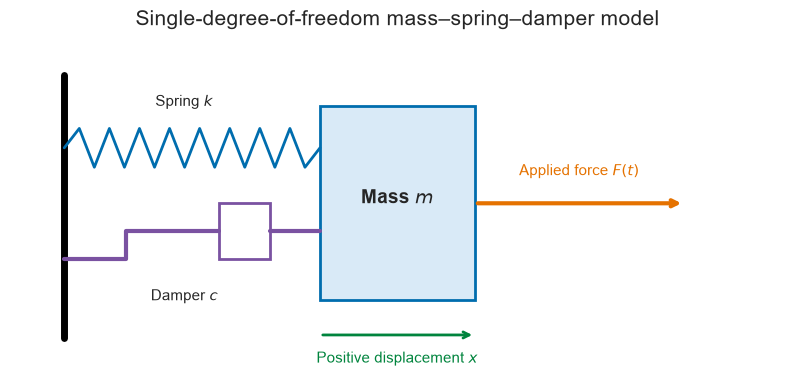

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 5)
ax.axis("off")

ax.plot([0.7, 0.7], [0.6, 4.4], color="black", linewidth=5)
spring_x = np.linspace(0.7, 4.0, 18)
spring_y = 3.35 + 0.28*np.where(
    np.arange(18) % 2 == 0, -1.0, 1.0
)
spring_y[[0, -1]] = 3.35
ax.plot(spring_x, spring_y, color=BLUE, linewidth=2)
ax.text(2.25, 3.95, "Spring $k$", ha="center")

ax.plot([0.7, 1.5, 1.5, 2.7], [1.75, 1.75, 2.15, 2.15],
        color=PURPLE, linewidth=3)
ax.add_patch(plt.Rectangle((2.7, 1.75), 0.65, 0.8, fill=False,
                           edgecolor=PURPLE, linewidth=2))
ax.plot([3.35, 4.0], [2.15, 2.15], color=PURPLE, linewidth=3)
ax.text(2.25, 1.15, "Damper $c$", ha="center")

mass = plt.Rectangle((4.0, 1.15), 2.0, 2.8, facecolor="#D9EAF7",
                     edgecolor=BLUE, linewidth=2)
ax.add_patch(mass)
ax.text(5.0, 2.55, "Mass $m$", ha="center", fontsize=14, weight="bold")
ax.annotate("", xy=(8.7, 2.55), xytext=(6.0, 2.55),
            arrowprops=dict(arrowstyle="->", color=ORANGE, linewidth=3))
ax.text(7.35, 2.95, "Applied force $F(t)$", ha="center", color=ORANGE)
ax.annotate("", xy=(6.0, 0.65), xytext=(4.0, 0.65),
            arrowprops=dict(arrowstyle="->", color=GREEN, linewidth=2))
ax.text(5.0, 0.25, "Positive displacement $x$", ha="center", color=GREEN)
ax.set_title("Single-degree-of-freedom mass–spring–damper model", fontsize=15)
plt.show()


### Dimensional check

Every term is a force:

$$
m\frac{d^2x}{dt^2}\ [\mathrm{N}],\qquad
c\frac{dx}{dt}\ [\mathrm{N}],\qquad
kx\ [\mathrm{N}],\qquad
F(t)\ [\mathrm{N}].
$$

The signs assume the spring and damper oppose positive displacement and velocity. A
different coordinate convention changes signs consistently, not selectively.


## 📂 7.5.2 Introduce—not silently replace—the state variables

Define two state components:

$$
y_1(t)=x(t),
\qquad
y_2(t)=\frac{dx}{dt}=v(t).
$$

We have not discarded or renamed displacement. $y_1$ is a state-vector label for the
same physical displacement $x$. The second state $y_2$ is introduced because knowing
position alone is insufficient to determine the future motion of a second-order
system.

Differentiate the definitions:

$$
\frac{dy_1}{dt}=y_2,
\qquad
\frac{dy_2}{dt}=\frac{d^2x}{dt^2}.
$$


### Isolate acceleration and substitute

Rearrange the original force balance:

$$
\frac{d^2x}{dt^2}
=\frac{F(t)-c\,dx/dt-kx}{m}.
$$

Now substitute $x=y_1$ and $dx/dt=y_2$:

$$
\boxed{
\begin{aligned}
\frac{dy_1}{dt} &= y_2,\\
\frac{dy_2}{dt} &= \frac{F(t)-c y_2-k y_1}{m}.
\end{aligned}}
$$

In vector form,

$$
\mathbf{y}(t)=
\begin{bmatrix}y_1(t)\\y_2(t)\end{bmatrix}
=\begin{bmatrix}x(t)\\v(t)\end{bmatrix},
\qquad
\frac{d\mathbf{y}}{dt}=
\begin{bmatrix}
v\\[2pt]
[F(t)-cv-kx]/m
\end{bmatrix}.
$$

The vector contains quantities with different units: metres and metres per second.
Its derivative contains metres per second and metres per second squared.


## 📂 7.5.3 Initial conditions for a second-order IVP

A second-order motion equation normally requires two scalar initial conditions:

$$
x(t_0)=x_0,
\qquad
v(t_0)=v_0.
$$

The first-order state IVP is therefore

$$
\frac{d\mathbf{y}}{dt}=\mathbf{f}(t,\mathbf{y}),
\qquad
\mathbf{y}(t_0)=
\begin{bmatrix}x_0\\v_0\end{bmatrix}.
$$

Two systems can begin at the same position but move differently if their initial
velocities differ. Position alone does not completely specify the mechanical state.


In [ ]:
initial_state = np.array([INITIAL_POSITION_M, INITIAL_VELOCITY_M_S])
initial_derivative = oscillator_rhs(0.0, initial_state)

labels = ["position x", "velocity v"]
derivative_labels = ["dx/dt = v", "dv/dt = acceleration"]
units = ["m", "m/s"]
derivative_units = ["m/s", "m/s²"]

print("State components at t=0:")
for index, (label, value, unit) in enumerate(zip(labels, initial_state, units)):
    print(f"  state[{index}] = {label:12s} = {value: .5f} {unit}")
print("\nReturned derivative components:")
for index, (label, value, unit) in enumerate(
    zip(derivative_labels, initial_derivative, derivative_units)
):
    print(f"  derivative[{index}] = {label:22s} = {value: .5f} {unit}")


State components at t=0:
  state[0] = position x   =  0.05000 m
  state[1] = velocity v   =  0.00000 m/s

Returned derivative components:
  derivative[0] = dx/dt = v              =  0.00000 m/s
  derivative[1] = dv/dt = acceleration   = -2.00000 m/s²


### ⚠️ State-component contract

`state[0]` and `state[1]` are two physical quantities at the **same current time**.
They are not consecutive data samples and not two experimental runs. During a solver
call, the entire state vector represents one candidate point in phase space.


## 📂 7.5.4 Solve the vector IVP

`solve_ivp` passes the current state array to the right-hand-side function and expects
a derivative array of the same shape. The output `solution.y` has one row per state
component and one column per reported time coordinate:

```text
solution.y[0, :]  -> position history
solution.y[1, :]  -> velocity history
```

The second index runs through time coordinates; the first selects the physical state.


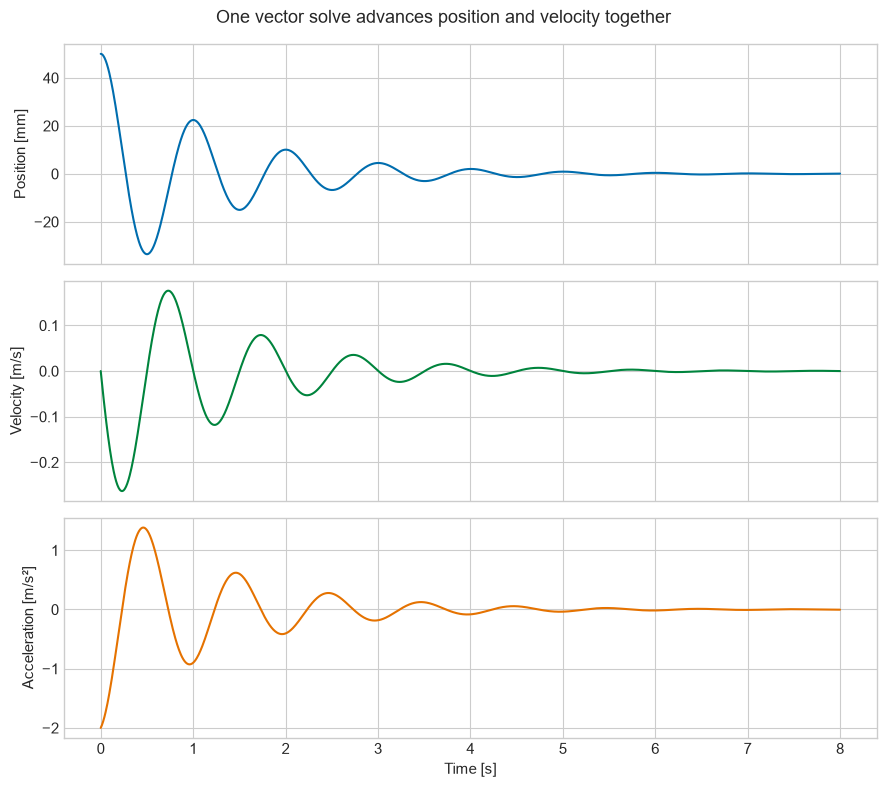

State-array shape: (2, 1201)
success: True
right-hand-side evaluations: 3374


In [ ]:
time_span = (0.0, 8.0)
display_time = np.linspace(*time_span, 1201)
free_solution = solve_ivp(
    oscillator_rhs,
    time_span,
    initial_state,
    method="RK45",
    t_eval=display_time,
    rtol=1e-9,
    atol=np.array([1e-11, 1e-10]),
)
position = free_solution.y[0]
velocity = free_solution.y[1]
acceleration = np.array([
    oscillator_rhs(t, free_solution.y[:, i])[1]
    for i, t in enumerate(free_solution.t)
])

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
axes[0].plot(free_solution.t, 1e3*position, color=BLUE)
axes[0].set_ylabel("Position [mm]")
axes[1].plot(free_solution.t, velocity, color=GREEN)
axes[1].set_ylabel("Velocity [m/s]")
axes[2].plot(free_solution.t, acceleration, color=ORANGE)
axes[2].set_xlabel("Time [s]")
axes[2].set_ylabel("Acceleration [m/s²]")
fig.suptitle("One vector solve advances position and velocity together")
fig.tight_layout()
plt.show()

print("State-array shape:", free_solution.y.shape)
print("success:", free_solution.success)
print("right-hand-side evaluations:", free_solution.nfev)


Acceleration is calculated from the governing force balance using the numerical
position and velocity. It is not stored as an independent state because its current
value is determined directly by $(t,x,v)$ and the model parameters.


## 📂 7.5.5 Natural frequency and damping ratio

For the unforced linear system, define

$$
\omega_n=\sqrt{\frac{k}{m}},
\qquad
\zeta=\frac{c}{2\sqrt{km}}.
$$

Here $\omega_n$ is the undamped natural angular frequency [rad/s] and $\zeta$ is the
dimensionless damping ratio.

* $0<\zeta<1$: underdamped oscillation;
* $\zeta=1$: critical damping; and
* $\zeta>1$: overdamped non-oscillatory return.

For an underdamped system, the damped angular frequency is

$$
\omega_d=\omega_n\sqrt{1-\zeta^2}.
$$


In [ ]:
natural_frequency_rad_s = np.sqrt(STIFFNESS_N_M/MASS_KG)
damping_ratio = DAMPING_N_S_M/(2*np.sqrt(STIFFNESS_N_M*MASS_KG))
damped_frequency_rad_s = natural_frequency_rad_s*np.sqrt(1-damping_ratio**2)

print(f"Natural angular frequency ω_n = {natural_frequency_rad_s:.4f} rad/s")
print(f"Natural frequency f_n = {natural_frequency_rad_s/(2*np.pi):.4f} Hz")
print(f"Damping ratio ζ = {damping_ratio:.4f}")
print(f"Damped angular frequency ω_d = {damped_frequency_rad_s:.4f} rad/s")


Natural angular frequency ω_n = 6.3246 rad/s
Natural frequency f_n = 1.0066 Hz
Damping ratio ζ = 0.1265
Damped angular frequency ω_d = 6.2738 rad/s


## 📂 7.5.6 Analytical verification for the underdamped case

For zero force and $0<\zeta<1$,

$$
x(t)=e^{-\zeta\omega_n t}
\left[
x_0\cos(\omega_d t)
+\frac{v_0+\zeta\omega_n x_0}{\omega_d}\sin(\omega_d t)
\right].
$$

This closed-form response is a verification reference for the numerical solver. It is
available because the model is linear with constant coefficients and zero forcing.


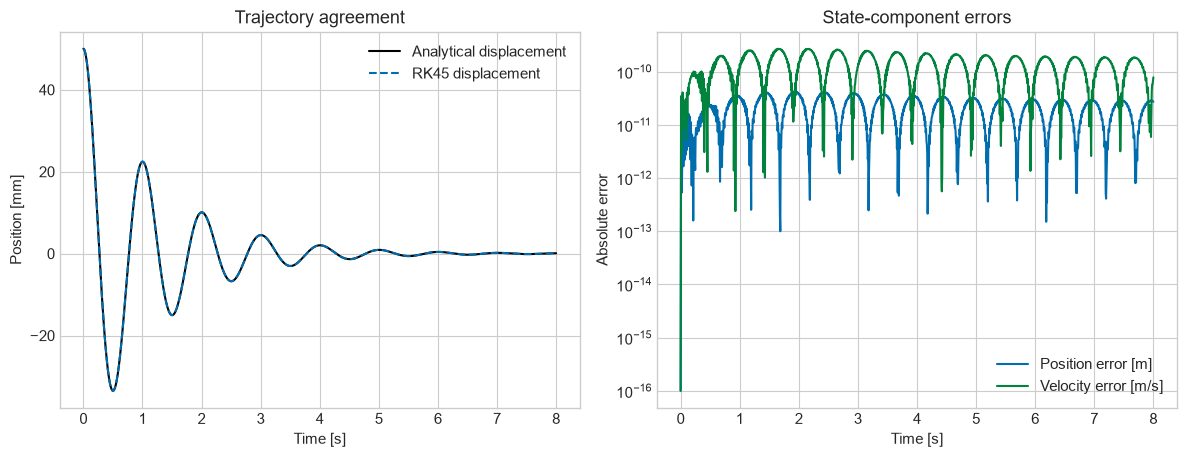

In [ ]:
def underdamped_exact(time_s, initial_position_m=INITIAL_POSITION_M,
                      initial_velocity_m_s=INITIAL_VELOCITY_M_S,
                      mass_kg=MASS_KG, damping_n_s_m=DAMPING_N_S_M,
                      stiffness_n_m=STIFFNESS_N_M):
    '''Return analytical displacement and velocity for an unforced underdamped SDOF.'''
    time_s = np.asarray(time_s, dtype=float)
    omega_n = np.sqrt(stiffness_n_m/mass_kg)
    zeta = damping_n_s_m/(2*np.sqrt(stiffness_n_m*mass_kg))
    if not 0 <= zeta < 1:
        raise ValueError("This formula requires an underdamped system")
    alpha = zeta*omega_n
    omega_d = omega_n*np.sqrt(1-zeta**2)
    A = initial_position_m
    B = (initial_velocity_m_s+alpha*initial_position_m)/omega_d
    cosine = np.cos(omega_d*time_s)
    sine = np.sin(omega_d*time_s)
    envelope = np.exp(-alpha*time_s)
    displacement = envelope*(A*cosine+B*sine)
    velocity = envelope*((-A*omega_d*sine+B*omega_d*cosine)
                         -alpha*(A*cosine+B*sine))
    return displacement, velocity

exact_position, exact_velocity = underdamped_exact(display_time)
position_error = free_solution.y[0]-exact_position
velocity_error = free_solution.y[1]-exact_velocity

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].plot(display_time, 1e3*exact_position, color="black",
             label="Analytical displacement")
axes[0].plot(display_time, 1e3*free_solution.y[0], "--", color=BLUE,
             label="RK45 displacement")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Position [mm]")
axes[0].set_title("Trajectory agreement")
axes[0].legend()

axes[1].semilogy(display_time, np.maximum(np.abs(position_error), 1e-16),
                 color=BLUE, label="Position error [m]")
axes[1].semilogy(display_time, np.maximum(np.abs(velocity_error), 1e-16),
                 color=GREEN, label="Velocity error [m/s]")
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Absolute error")
axes[1].set_title("State-component errors")
axes[1].legend()
fig.tight_layout()
plt.show()


### 🧠 Verification versus validation

Agreement with the analytical solution verifies the numerical implementation for this
idealised model. It does not validate linear damping, constant stiffness or a
single-degree-of-freedom representation against a physical structure.


## 📂 7.5.7 Compare damping regimes

The critical damping coefficient is

$$
c_{\mathrm{crit}}=2\sqrt{km}.
$$

We hold $m$, $k$, $x_0$ and $v_0$ fixed and vary only $c$. This isolates how the
damping ratio changes the free response.


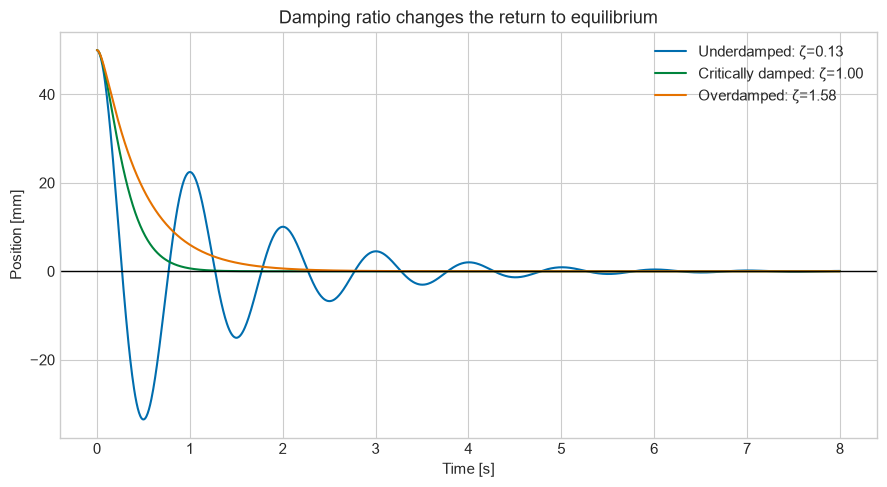

In [ ]:
critical_damping = 2*np.sqrt(STIFFNESS_N_M*MASS_KG)
damping_cases = [
    (8.0, "Underdamped", BLUE),
    (critical_damping, "Critically damped", GREEN),
    (100.0, "Overdamped", ORANGE),
]

plt.figure(figsize=(9, 5))
for damping, label, color in damping_cases:
    def case_rhs(time_s, state, damping_value=damping):
        return oscillator_rhs(
            time_s, state, damping_n_s_m=damping_value
        )

    case_solution = solve_ivp(
        case_rhs, time_span, initial_state, t_eval=display_time,
        rtol=1e-8, atol=[1e-10, 1e-9]
    )
    zeta = damping/(2*np.sqrt(STIFFNESS_N_M*MASS_KG))
    plt.plot(display_time, 1e3*case_solution.y[0], color=color,
             label=f"{label}: ζ={zeta:.2f}")
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Time [s]")
plt.ylabel("Position [mm]")
plt.title("Damping ratio changes the return to equilibrium")
plt.legend()
plt.tight_layout()
plt.show()


Critical damping is the fastest non-oscillatory return for this ideal second-order
model. “More damping is faster” is not generally correct: the overdamped case returns
more slowly because the damper strongly resists motion.


## 📂 7.5.8 Phase space shows the complete state

A time plot shows how one variable changes. A **phase-plane** plot places velocity
against displacement so every point represents the complete two-component state

$$
\mathbf{y}=\begin{bmatrix}x\\v\end{bmatrix}.
$$

For the damped unforced oscillator, the trajectory spirals toward $(x,v)=(0,0)$ as
mechanical energy is dissipated.


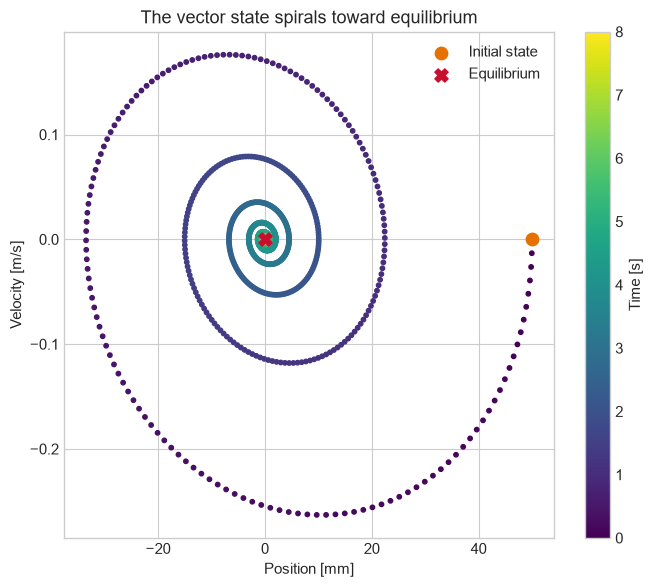

In [ ]:
plt.figure(figsize=(7, 6))
points = plt.scatter(1e3*position, velocity, c=free_solution.t,
                     cmap="viridis", s=10)
plt.scatter(1e3*position[0], velocity[0], color=ORANGE, s=80,
            label="Initial state", zorder=4)
plt.scatter(0, 0, color=RED, marker="X", s=90,
            label="Equilibrium", zorder=5)
plt.xlabel("Position [mm]")
plt.ylabel("Velocity [m/s]")
plt.title("The vector state spirals toward equilibrium")
plt.colorbar(points, label="Time [s]")
plt.legend()
plt.tight_layout()
plt.show()


Two times can have the same displacement but different velocities. They are different
states and therefore generally have different futures. This is why displacement alone
is insufficient as the state of a second-order mechanical IVP.


## 📂 7.5.9 Energy provides an independent physical check

For zero external force, mechanical energy is

$$
E(t)=\frac12 m v^2+\frac12 kx^2.
$$

Differentiate and use the governing equation:

$$
\frac{dE}{dt}
=v(m\,dv/dt+kx)
=-c v^2\le0.
$$

The damper removes energy at rate $c v^2$ [W]. A numerically generated increase in
total energy for this unforced positive-damping system would require investigation.


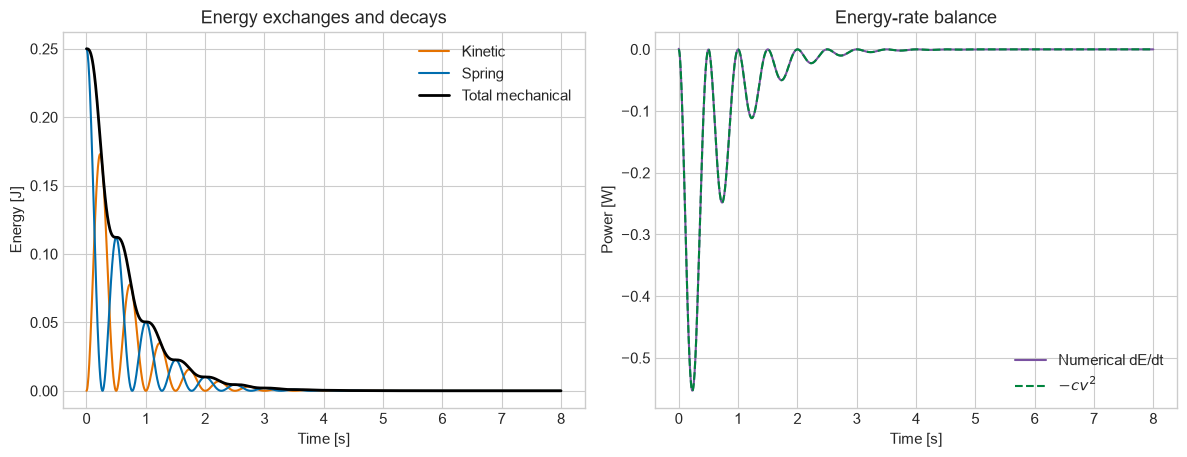

In [ ]:
kinetic_energy = 0.5*MASS_KG*velocity**2
spring_energy = 0.5*STIFFNESS_N_M*position**2
total_energy = kinetic_energy+spring_energy
dissipated_power = DAMPING_N_S_M*velocity**2

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].plot(display_time, kinetic_energy, color=ORANGE, label="Kinetic")
axes[0].plot(display_time, spring_energy, color=BLUE, label="Spring")
axes[0].plot(display_time, total_energy, color="black", linewidth=2,
             label="Total mechanical")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Energy [J]")
axes[0].set_title("Energy exchanges and decays")
axes[0].legend()

numerical_dE_dt = np.gradient(total_energy, display_time, edge_order=2)
axes[1].plot(display_time, numerical_dE_dt, color=PURPLE,
             label="Numerical dE/dt")
axes[1].plot(display_time, -dissipated_power, "--", color=GREEN,
             label="$-cv^2$")
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Power [W]")
axes[1].set_title("Energy-rate balance")
axes[1].legend()
fig.tight_layout()
plt.show()


Small differences near sharp extrema arise because `np.gradient` estimates $dE/dt$
from a finite output grid. Refining the displayed coordinates should reduce this
derivative discrepancy until solver, interpolation or round-off errors dominate.


## 📂 7.5.10 Prescribed forcing enters the acceleration equation

Let

$$
F(t)=F_0\sin(\omega_F t).
$$

The force does not create an additional state because its value is prescribed at every
time. It enters only the acceleration equation:

$$
\frac{dv}{dt}=\frac{F_0\sin(\omega_F t)-cv-kx}{m}.
$$

If an actuator or controller had its own dynamics, those dynamics could introduce
additional states.


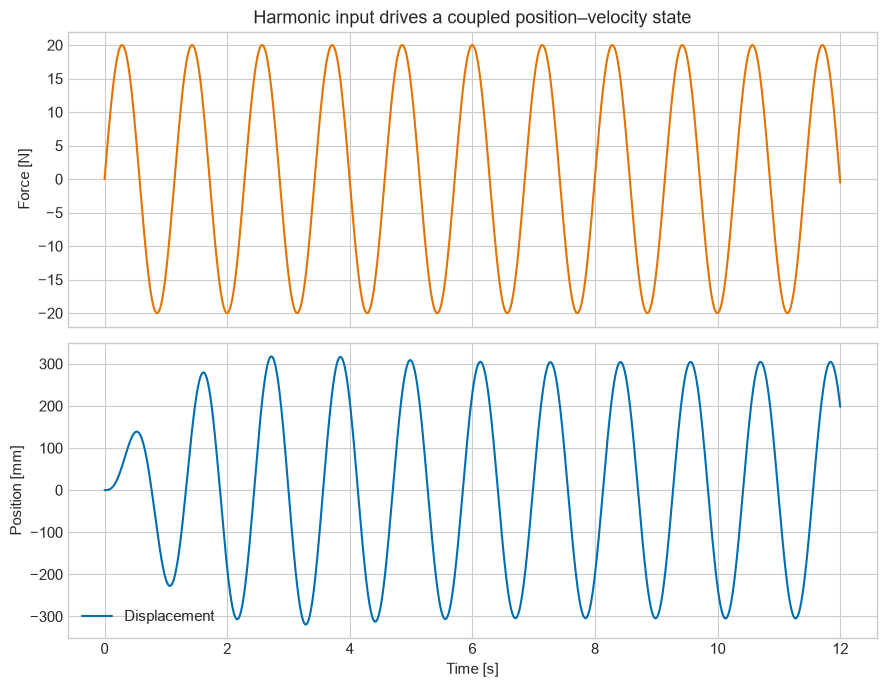

In [ ]:
FORCE_AMPLITUDE_N = 20.0
FORCE_FREQUENCY_RAD_S = 5.5

def harmonic_force(time_s):
    return FORCE_AMPLITUDE_N*np.sin(FORCE_FREQUENCY_RAD_S*time_s)

def forced_rhs(time_s, state):
    return oscillator_rhs(time_s, state, force_function=harmonic_force)

forced_time = np.linspace(0.0, 12.0, 1801)
forced_solution = solve_ivp(
    forced_rhs, (0.0, 12.0), [0.0, 0.0], t_eval=forced_time,
    method="RK45", rtol=1e-8, atol=[1e-10, 1e-9]
)
force_history = harmonic_force(forced_time)

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(forced_time, force_history, color=ORANGE)
axes[0].set_ylabel("Force [N]")
axes[0].set_title("Harmonic input drives a coupled position–velocity state")
axes[1].plot(forced_time, 1e3*forced_solution.y[0], color=BLUE,
             label="Displacement")
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Position [mm]")
axes[1].legend()
fig.tight_layout()
plt.show()


The response contains a transient determined by the initial state and a continuing
forced response determined by the input frequency. Changing $F(t)$ changes the
trajectory, not the definitions of the mechanical state variables.

The predicted displacement is much larger than the earlier free response because the
forcing frequency is near the natural frequency. In a real rig, available spring
travel, geometric nonlinearity, friction and force limits must be checked before
accepting such a large response from this linear model.


## 📂 7.5.11 State-space matrix form

The same linear state equations can be written

$$
\frac{d\mathbf{y}}{dt}
=\mathbf{A}\mathbf{y}+\mathbf{B}F(t),
$$

with

$$
\mathbf{A}=
\begin{bmatrix}
0 & 1\\
-k/m & -c/m
\end{bmatrix},
\qquad
\mathbf{B}=
\begin{bmatrix}
0\\1/m
\end{bmatrix}.
$$

Matrix form reorganises the same two scalar equations. It is useful for coupled
systems, controls and eigenvalue analysis, but it does not change the physics.


In [ ]:
A_matrix = np.array([
    [0.0, 1.0],
    [-STIFFNESS_N_M/MASS_KG, -DAMPING_N_S_M/MASS_KG],
])
B_vector = np.array([0.0, 1.0/MASS_KG])

example_time = 0.35
example_state = np.array([0.020, -0.080])
matrix_derivative = A_matrix@example_state + B_vector*harmonic_force(example_time)
function_derivative = forced_rhs(example_time, example_state)

print("A matrix:\n", A_matrix)
print("B vector:", B_vector)
print("Matrix derivative:", matrix_derivative)
print("Function derivative:", function_derivative)
print("Forms agree:", np.allclose(matrix_derivative, function_derivative))


A matrix:
 [[  0.    1. ]
 [-40.   -1.6]]
B vector: [0.  0.2]
Matrix derivative: [-0.08        3.07969195]
Function derivative: [-0.08        3.07969195]
Forms agree: True


## 📂 7.5.12 States and measured outputs are not always identical

Suppose a displacement sensor measures only

$$
z(t)=x(t).
$$

In state-space notation,

$$
z(t)=
\begin{bmatrix}1&0\end{bmatrix}
\mathbf{y}(t).
$$

The model still evolves both $x$ and $v$. Velocity is a hidden state relative to this
dataset: it affects future displacement even though it is not measured directly.
Additional sensors could provide velocity or acceleration outputs, but they do not
automatically create additional independent states.


## 📂 7.5.13 Calibrate stiffness and damping from displacement data

Assume mass and initial conditions are known, while $c$ and $k$ are uncertain. An
experiment records displacement at irregular times:

$$
\mathcal{D}_{\mathrm{train}}=
\{(t_i,x_i^{\mathrm{meas}})\}_{i=1}^{N}.
$$

For each candidate $(c,k)$, the optimizer solves the two-state IVP, evaluates the
displacement output at $t_i$, and minimises normalised residuals. It does not fit an
independent velocity or displacement coefficient at every time point.


In [ ]:
rng = np.random.default_rng(75)
training_times = np.sort(np.concatenate([
    np.array([0.0, 8.0]), rng.uniform(0.15, 7.85, 38)
]))
true_training_position, _ = underdamped_exact(training_times)
displacement_noise_m = 0.00045
training_displacement = true_training_position + rng.normal(
    0.0, displacement_noise_m, training_times.size
)

def predict_displacement(times, damping_n_s_m, stiffness_n_m,
                         initial_position_m, initial_velocity_m_s):
    '''Solve the candidate state model and return displacement at requested times.'''
    times = np.asarray(times, dtype=float)

    def candidate_rhs(time_s, state):
        return oscillator_rhs(
            time_s, state,
            damping_n_s_m=damping_n_s_m,
            stiffness_n_m=stiffness_n_m,
        )

    solution = solve_ivp(
        candidate_rhs, (times[0], times[-1]),
        [initial_position_m, initial_velocity_m_s],
        method="RK45", rtol=2e-7, atol=[1e-9, 1e-8],
        dense_output=True,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    return solution.sol(times)[0]

def parameter_residual(parameters):
    damping, stiffness = parameters
    prediction = predict_displacement(
        training_times, damping, stiffness,
        INITIAL_POSITION_M, INITIAL_VELOCITY_M_S
    )
    return (prediction-training_displacement)/displacement_noise_m

fit = least_squares(
    parameter_residual,
    x0=np.array([12.0, 170.0]),
    bounds=([0.2, 80.0], [50.0, 400.0]),
    x_scale="jac",
)
fitted_damping, fitted_stiffness = fit.x
fitted_training = predict_displacement(
    training_times, fitted_damping, fitted_stiffness,
    INITIAL_POSITION_M, INITIAL_VELOCITY_M_S
)
training_rmse = np.sqrt(np.mean(
    (fitted_training-training_displacement)**2
))

print(f"True c = {DAMPING_N_S_M:.3f} N·s/m; fitted c = {fitted_damping:.3f} N·s/m")
print(f"True k = {STIFFNESS_N_M:.3f} N/m; fitted k = {fitted_stiffness:.3f} N/m")
print(f"Training displacement RMSE = {1e3*training_rmse:.3f} mm")


True c = 8.000 N·s/m; fitted c = 7.832 N·s/m
True k = 200.000 N/m; fitted k = 200.185 N/m
Training displacement RMSE = 0.417 mm


### Why can displacement contain information about both parameters?

With mass known:

* oscillation frequency provides information about $k/m$; and
* decay of the response envelope provides information about $c/m$.

If $m$, $c$ and $k$ were all unknown from only this free-response dataset, their ratios
could be better identified than their absolute values. Parameter identifiability
depends on the measured outputs, known quantities, initial conditions, excitation,
test duration and noise—not only on the optimizer.


## 📂 7.5.14 Validate on a new initial state

A model should be tested outside the calibration trajectory. The fitted $c$ and $k$
are now held fixed while the system begins from a different displacement and non-zero
velocity. No parameter refitting is permitted in the validation panel.


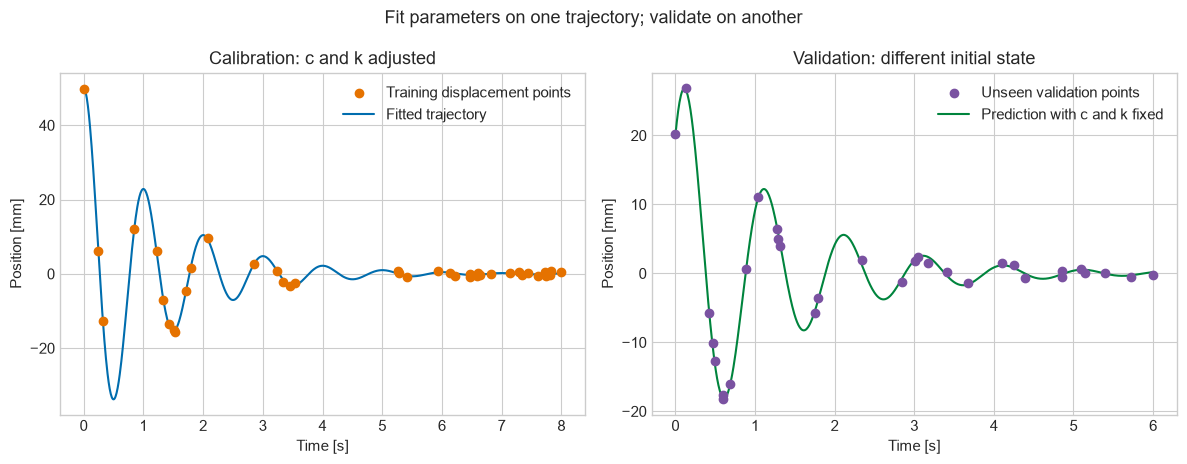

Validation displacement RMSE = 0.451 mm


In [ ]:
validation_initial_position = 0.020
validation_initial_velocity = 0.120
validation_times = np.sort(np.concatenate([
    np.array([0.0, 6.0]), rng.uniform(0.10, 5.90, 30)
]))
validation_true, _ = underdamped_exact(
    validation_times,
    initial_position_m=validation_initial_position,
    initial_velocity_m_s=validation_initial_velocity,
)
validation_data = validation_true + rng.normal(
    0.0, displacement_noise_m, validation_times.size
)
validation_prediction = predict_displacement(
    validation_times, fitted_damping, fitted_stiffness,
    validation_initial_position, validation_initial_velocity
)
validation_rmse = np.sqrt(np.mean(
    (validation_prediction-validation_data)**2
))

dense_training = np.linspace(0.0, 8.0, 900)
dense_validation = np.linspace(0.0, 6.0, 700)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].scatter(training_times, 1e3*training_displacement, color=ORANGE,
                label="Training displacement points", zorder=3)
axes[0].plot(
    dense_training,
    1e3*predict_displacement(
        dense_training, fitted_damping, fitted_stiffness,
        INITIAL_POSITION_M, INITIAL_VELOCITY_M_S
    ),
    color=BLUE, label="Fitted trajectory"
)
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Position [mm]")
axes[0].set_title("Calibration: c and k adjusted")
axes[0].legend()

axes[1].scatter(validation_times, 1e3*validation_data, color=PURPLE,
                label="Unseen validation points", zorder=3)
axes[1].plot(
    dense_validation,
    1e3*predict_displacement(
        dense_validation, fitted_damping, fitted_stiffness,
        validation_initial_position, validation_initial_velocity
    ),
    color=GREEN, label="Prediction with c and k fixed"
)
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Position [mm]")
axes[1].set_title("Validation: different initial state")
axes[1].legend()
fig.suptitle("Fit parameters on one trajectory; validate on another")
fig.tight_layout()
plt.show()

print(f"Validation displacement RMSE = {1e3*validation_rmse:.3f} mm")


### 🧠 Data interpretation

The displacement points constrain a two-state model even though velocity is not
measured. This does not mean the hidden velocity has been observed directly. Its
inferred trajectory depends on the ODE structure, fitted parameters, initial
conditions and numerical solution.


## 📂 7.5.15 Model acceleration versus differentiating noisy position

Once the state trajectory and parameters are available, the ODE provides

$$
a(t)=\frac{F(t)-cv(t)-kx(t)}{m}.
$$

Alternatively, acceleration could be estimated by differentiating measured position
twice. Notebook 7.1 showed that each differentiation amplifies measurement noise. The
model-based acceleration is smoother because it is constrained by the assumed ODE;
it is not automatically more truthful if the model or parameters are wrong.


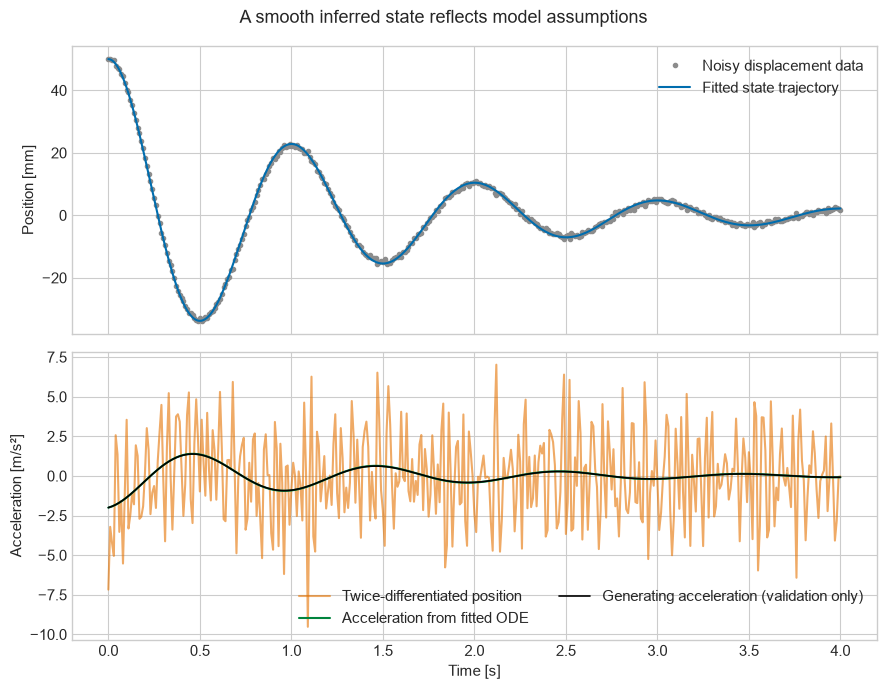

In [ ]:
uniform_sensor_time = np.linspace(0.0, 4.0, 401)
true_sensor_position, true_sensor_velocity = underdamped_exact(uniform_sensor_time)
noisy_sensor_position = true_sensor_position + rng.normal(
    0.0, displacement_noise_m, uniform_sensor_time.size
)
data_acceleration = np.gradient(
    np.gradient(noisy_sensor_position, uniform_sensor_time, edge_order=2),
    uniform_sensor_time, edge_order=2
)

fitted_position = predict_displacement(
    uniform_sensor_time, fitted_damping, fitted_stiffness,
    INITIAL_POSITION_M, INITIAL_VELOCITY_M_S
)
# Re-solve to retain the hidden fitted velocity state.
def fitted_rhs(time_s, state):
    return oscillator_rhs(
        time_s, state,
        damping_n_s_m=fitted_damping,
        stiffness_n_m=fitted_stiffness,
    )
fitted_state_solution = solve_ivp(
    fitted_rhs, (0.0, 4.0), initial_state,
    t_eval=uniform_sensor_time, rtol=2e-8, atol=[1e-10, 1e-9]
)
fitted_velocity = fitted_state_solution.y[1]
model_acceleration = (
    -fitted_damping*fitted_velocity-fitted_stiffness*fitted_position
)/MASS_KG
true_acceleration = (
    -DAMPING_N_S_M*true_sensor_velocity-STIFFNESS_N_M*true_sensor_position
)/MASS_KG

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(uniform_sensor_time, 1e3*noisy_sensor_position, ".",
             color="0.55", label="Noisy displacement data")
axes[0].plot(uniform_sensor_time, 1e3*fitted_position, color=BLUE,
             label="Fitted state trajectory")
axes[0].set_ylabel("Position [mm]")
axes[0].legend()

axes[1].plot(uniform_sensor_time, data_acceleration, color=ORANGE, alpha=0.6,
             label="Twice-differentiated position")
axes[1].plot(uniform_sensor_time, model_acceleration, color=GREEN,
             label="Acceleration from fitted ODE")
axes[1].plot(uniform_sensor_time, true_acceleration, color="black", linewidth=1.2,
             label="Generating acceleration (validation only)")
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Acceleration [m/s²]")
axes[1].legend(ncols=2)
fig.suptitle("A smooth inferred state reflects model assumptions")
fig.tight_layout()
plt.show()


## 📂 7.5.16 General conversion of an $n$th-order ODE

Suppose a scalar ODE contains $x^{(n)}$, the $n$th derivative of $x$. Define

$$
y_1=x,
\quad y_2=\frac{dx}{dt},
\quad y_3=\frac{d^2x}{dt^2},
\quad\ldots\quad,
y_n=\frac{d^{n-1}x}{dt^{n-1}}.
$$

Then

$$
\frac{dy_1}{dt}=y_2,\quad
\frac{dy_2}{dt}=y_3,\quad\ldots\quad,
\frac{dy_{n-1}}{dt}=y_n.
$$

Rearrange the original ODE to express $x^{(n)}$ in terms of time and the lower
derivatives. That expression becomes $dy_n/dt$. An $n$th-order scalar IVP generally
requires $n$ initial values and becomes an $n$-component first-order system.


### Example: a third-order equation

If

$$
x''' + a_2x''+a_1x'+a_0x=u(t),
$$

define $y_1=x$, $y_2=x'$ and $y_3=x''$. The system is

$$
\frac{d}{dt}
\begin{bmatrix}y_1\\y_2\\y_3\end{bmatrix}
=
\begin{bmatrix}
y_2\\
y_3\\
u(t)-a_2y_3-a_1y_2-a_0y_1
\end{bmatrix}.
$$

The new labels record derivative order. They do not introduce three independent
physical objects unless the original model supports that interpretation.


## 📂 7.5.17 State scaling and component tolerances

Position [m] and velocity [m/s] have different units and may have different numerical
magnitudes. For adaptive integration, SciPy uses component-wise scales

$$
\mathrm{atol}_j+\mathrm{rtol}|y_j|.
$$

A vector `atol` allows a physically meaningful absolute tolerance for each state:

```python
atol = np.array([position_tolerance_m, velocity_tolerance_m_s])
```

Tolerances should be tighter than required numerical accuracy but need not be far below
sensor resolution or model uncertainty. Convergence of decision-relevant outputs must
still be checked.


## 📂 7.5.18 Common failure modes and checks

* **Wrong state order:** returning `[acceleration, velocity]` when the state is
  `[position, velocity]` silently changes the model.
* **Missing initial derivative:** a second-order IVP is incomplete without initial
  position and velocity.
* **State/sample confusion:** `state[1]` is velocity now, not displacement at the next
  time point.
* **Unit inconsistency:** every state derivative must match its component per second.
* **Unmeasured-state certainty:** a smooth hidden-state estimate is conditional on the
  model and parameters.
* **Parameter non-identifiability:** a good output fit may not uniquely determine every
  physical parameter.
* **Numerical masking:** loose tolerances can be absorbed by fitted parameters.
* **Missing physics:** nonlinear stiffness, dry friction or additional modes cannot be
  repaired merely by refining RK45.

Use analytical limits, force balance, energy, convergence and independent experiments
as complementary checks.


## 📂 7.5.19 Optional interactive damping and initial-state demonstration

Adjust damping and initial velocity. Observe both the time trajectory and phase plane.
The state always remains `[position, velocity]`; the controls change parameters or the
initial condition, not the state definition.


In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    def oscillator_explorer(damping_n_s_m=8.0, initial_velocity_m_s=0.0):
        def interactive_rhs(time_s, state):
            return oscillator_rhs(
                time_s, state, damping_n_s_m=damping_n_s_m
            )

        t_plot = np.linspace(0.0, 8.0, 1001)
        result = solve_ivp(
            interactive_rhs, (0.0, 8.0),
            [INITIAL_POSITION_M, initial_velocity_m_s],
            t_eval=t_plot, rtol=1e-7, atol=[1e-9, 1e-8]
        )
        zeta = damping_n_s_m/(2*np.sqrt(STIFFNESS_N_M*MASS_KG))

        fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
        axes[0].plot(t_plot, 1e3*result.y[0], color=BLUE)
        axes[0].axhline(0, color="black", linewidth=0.8)
        axes[0].set_xlabel("Time [s]")
        axes[0].set_ylabel("Position [mm]")
        axes[0].set_title(f"Time response, ζ={zeta:.2f}")

        axes[1].plot(1e3*result.y[0], result.y[1], color=PURPLE)
        axes[1].scatter(1e3*result.y[0, 0], result.y[1, 0],
                        color=ORANGE, label="Initial state")
        axes[1].scatter(0, 0, color=RED, marker="X", label="Equilibrium")
        axes[1].set_xlabel("Position [mm]")
        axes[1].set_ylabel("Velocity [m/s]")
        axes[1].set_title("Phase plane")
        axes[1].legend()
        fig.tight_layout()
        plt.show()

    controls = {
        "damping_n_s_m": widgets.FloatSlider(
            value=8.0, min=0.0, max=100.0, step=2.0,
            description="c [N·s/m]", continuous_update=False
        ),
        "initial_velocity_m_s": widgets.FloatSlider(
            value=0.0, min=-0.3, max=0.3, step=0.03,
            description="v₀ [m/s]", continuous_update=False
        ),
    }
    output = widgets.interactive_output(oscillator_explorer, controls)
    display(widgets.VBox([widgets.HBox(list(controls.values())), output]))
except ImportError:
    print("ipywidgets is unavailable; all static demonstrations remain complete.")


## 📂 7.5.20 Useful packages and functions

| Tool | Purpose | Important note |
|---|---|---|
| `np.array([x, v])` | Constructs the current state vector | Components may have different physical units |
| `solve_ivp(fun, t_span, y0)` | Advances a first-order state system | `fun` must return the same state shape |
| Vector `atol` | Sets component-specific absolute scales | Match units and engineering accuracy needs |
| `dense_output=True` | Evaluates hidden and measured states at requested times | Interpolated predictions are not observations |
| `least_squares(...)` | Calibrates parameters from output residuals | Check bounds, identifiability and independent validation |
| `np.gradient(...)` | Estimates derivatives from sampled outputs | Repeated differentiation strongly amplifies noise |

Solver success is necessary but not sufficient. Always inspect state ordering, output
mapping, physical balances, numerical convergence and validation evidence.


## 📂 7.5.21 Engineering workflow and summary

### Higher-order ODE workflow

1. Write the governing higher-order equation and define units and signs.
2. Identify the highest derivative and isolate it algebraically.
3. Introduce one state for the original variable and each lower derivative.
4. Write one first-order derivative equation for every state component.
5. Supply one initial value per state component.
6. Implement and hand-check the vector right-hand side at an interpretable state.
7. Solve with component-appropriate tolerances and inspect diagnostics.
8. Verify using analytical solutions, force balance, energy and convergence.
9. Map states to the outputs actually measured by sensors.
10. Calibrate uncertain parameters on informative data and validate without refitting.

### Key definitions

* ODE order is determined by the highest derivative.
* A state vector contains the minimum evolving quantities needed to determine the
  future under the model.
* A hidden state is evolved by the model but not directly measured in the dataset.
* Higher-order scalar ODEs become coupled first-order systems by explicit state
  definitions and substitution.

### Method review

The second-order mass–spring–damper equation became a two-state position–velocity
system. The same RK45 solver advanced both components together. Natural frequency,
damping regime, phase space and energy supplied physical interpretation and checks.
Displacement-only data calibrated stiffness and damping while velocity remained a
model-dependent hidden state, and a separate initial condition tested prediction
without parameter refitting.


## 🔗 Week 7 completion bridge

Week 7 has now connected five ideas:

1. finite differences estimate derivatives from sampled values;
2. ODEs specify how model states change;
3. Euler advances a state using one local slope;
4. Runge-Kutta methods combine several slopes and adapt step size; and
5. higher-order mechanical equations become first-order state systems.

The Week 7 workbook will use A activities to explore these behaviours and B activities
to select, justify and validate numerical methods for engineering problems. It will
preserve the distinction between experimental data points, state components, internal
numerical steps and fitted parameters.


## 📚 References

1. SciPy Developers, [`scipy.integrate.solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), accessed 2026.
2. SciPy Developers, [`scipy.optimize.least_squares`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html), accessed 2026.
3. NumPy Developers, [`numpy.gradient`](https://numpy.org/doc/stable/reference/generated/numpy.gradient.html), accessed 2026.
